# Prophet adapter

Use any foundation model inside an existing [Prophet](https://github.com/facebook/prophet) pipeline.
[`FoundationProphet`](../prophet-adapter.md) is a `prophet.Prophet` subclass: `fit`,
`make_future_dataframe`, `predict`, `plot` and Prophet's diagnostics keep working, but the forecasts come from
the foundation model you pass. See [Prophet adapter](../prophet-adapter.md) for the full API.

In [1]:
!UV_CONSTRAINT= UV_BUILD_CONSTRAINT= uv pip install -q "foundationforecast[prophet,plot]"

**Dataset:** monthly airline passengers (`ds`, `y`), a single series in the format Prophet expects.

## Import libraries

In [2]:
import matplotlib.pyplot as plt
import pandas as pd
from prophet import Prophet
from prophet.diagnostics import cross_validation, performance_metrics

from foundationforecast.models import Chronos
from foundationforecast.prophet import FoundationProphet

/Users/azul/projects/foundationforecast/.venv/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


INFO:datasets:JAX version 0.7.1 available.


## Load the dataset

In [3]:
df = pd.read_csv(
    "https://timecopilot.s3.amazonaws.com/public/data/air_passengers.csv",
    parse_dates=["ds"],
)
df.tail()

,unique_id,ds,y
139,AirPassengers,1960-08-01,606
140,AirPassengers,1960-09-01,508
141,AirPassengers,1960-10-01,461
142,AirPassengers,1960-11-01,390
143,AirPassengers,1960-12-01,432


## The Prophet pipeline

A typical Prophet pipeline: fit, build a future dataframe, predict.

In [4]:
m = Prophet()
m.fit(df)
future = m.make_future_dataframe(periods=24, freq="MS")
prophet_fcst = m.predict(future)
prophet_fcst[["ds", "yhat", "yhat_lower", "yhat_upper"]].tail()

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


INFO:cmdstanpy:Chain [1] start processing


INFO:cmdstanpy:Chain [1] done processing


,ds,yhat,yhat_lower,yhat_upper
163,1962-08-01,614.080638,583.761798,642.744228
164,1962-09-01,566.191635,538.297700,596.918438
165,1962-10-01,530.475152,500.423265,559.342611
166,1962-11-01,497.641421,468.361675,527.594077
167,1962-12-01,527.185351,499.383324,555.062584


## Swap in a foundation model

Replace `Prophet()` with `FoundationProphet(model=...)`. The rest of the pipeline does not change.
Here the model is Chronos-Bolt; any foundationforecast model works the same way.

`include_history=False` keeps this first example to the forecast itself. Historical rows are covered in the
next section.

In [5]:
model = Chronos(repo_id="amazon/chronos-bolt-tiny", alias="Chronos-Bolt")

m = FoundationProphet(model=model)  # instead of Prophet()
m.fit(df)
future = m.make_future_dataframe(periods=24, freq="MS", include_history=False)
fcst = m.predict(future)
fcst.head()

Loading weights:   0%|          | 0/101 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 101/101 [00:00<00:00, 5927.14it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00,  7.15it/s]

100%|██████████| 1/1 [00:00<00:00,  7.12it/s]

,ds,yhat,yhat_lower,yhat_upper
0,1961-01-01,456.539276,426.958191,490.933838
1,1961-02-01,469.483185,437.416504,504.400208
2,1961-03-01,483.325195,447.063507,521.030762
3,1961-04-01,493.486450,454.987793,531.074158
4,1961-05-01,511.929626,474.540649,549.301025


`predict` returns Prophet's `ds`, `yhat`, `yhat_lower` and `yhat_upper`. The interval follows
`interval_width` (80% by default), converted to the model's `level`.

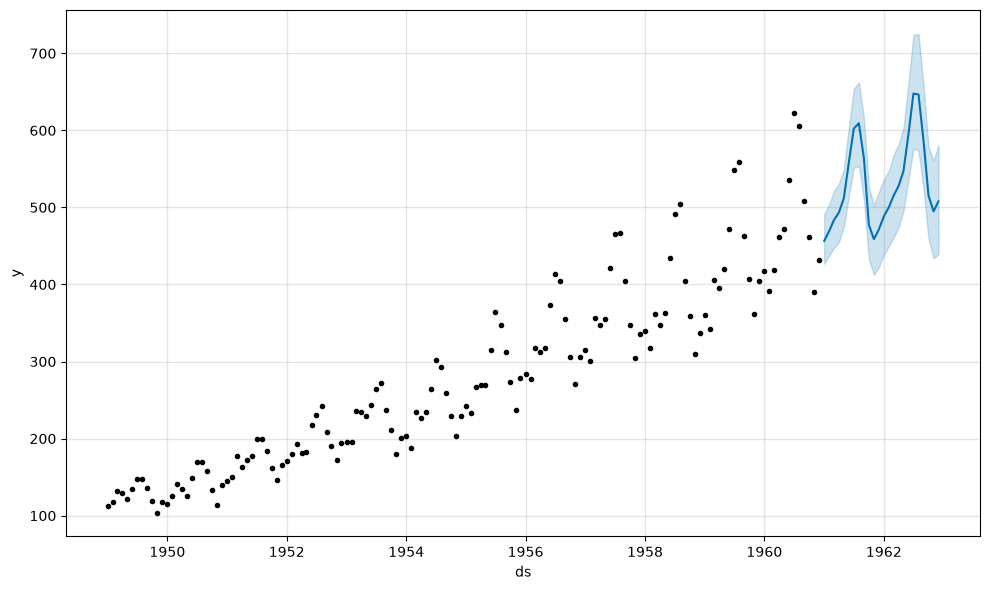

In [6]:
fig = m.plot(fcst)
plt.show()

## Historical rows

Foundation models are zero-shot, so there are no fitted values for the historical dates, yet
`make_future_dataframe` includes them by default. With `insample="cv"` (the default),
`FoundationProphet` fills them with rolling-origin backtest forecasts from `model.cross_validation`, and
logs what it is doing the first time. `insample_h` and `insample_n_windows` control the windows;
rows outside them are `NaN`.

In [7]:
m = FoundationProphet(model=model, insample_n_windows=4)
m.fit(df)
future_with_history = m.make_future_dataframe(periods=24, freq="MS")
fcst_with_history = m.predict(future_with_history)
first = fcst_with_history["yhat"].first_valid_index()
fcst_with_history.iloc[first - 2 : first + 2]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 80.48it/s]

0it [00:00, ?it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 93.14it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

... (3 outputs left out)

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 92.23it/s]


4it [00:00, 46.22it/s]

,ds,yhat,yhat_lower,yhat_upper
46,1952-11-01,NaN,NaN,NaN
47,1952-12-01,NaN,NaN,NaN
48,1953-01-01,190.890625,168.270203,210.872452
49,1953-02-01,195.221756,167.391754,220.558899


In [8]:
fcst_with_history["yhat"].notna().sum(), len(fcst_with_history)

(120, 168)

To skip the backtest, use `make_future_dataframe(include_history=False)` as above, or set
`insample="none"` so historical rows are `NaN` and the model only runs for the future dates.

In [9]:
m = FoundationProphet(model=model, insample="none")
m.fit(df)
fcst_none = m.predict(m.make_future_dataframe(periods=24, freq="MS"))
fcst_none["yhat"].isna().sum()

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 175.77it/s]

144

## Known-future regressors

Columns registered with `add_regressor` are passed to the model as known-future exogenous variables, so the
model must support them (here Chronos-2; see [Exogenous variables](../exogenous-variables.md)).
`predict` needs a value for every future period.

This example forecasts the next 24 hours of the Belgian electricity price (a fev-bench EPF market) using two
covariates, `ex_1` and `ex_2`, that are known in advance.

In [10]:
base = "https://timecopilot.s3.amazonaws.com/public/data/electricity_price/"
epf = pd.read_parquet(base + "train.parquet").query("unique_id == 'BE'").drop(columns="unique_id")
epf_future = pd.read_parquet(base + "futr_exog.parquet").query("unique_id == 'BE'").drop(columns="unique_id")
epf = epf.tail(24 * 28)
epf.tail()

,ds,y,ex_1,ex_2
51931,2016-12-11 19:00:00,52.720001,63185.0,68140.0
51932,2016-12-11 20:00:00,50.580002,62894.0,67186.0
51933,2016-12-11 21:00:00,42.439999,61190.0,64117.0
51934,2016-12-11 22:00:00,44.110001,59907.0,61451.0
51935,2016-12-11 23:00:00,42.060001,59827.0,65720.0


In [11]:
m = FoundationProphet(
    model=Chronos(repo_id="amazon/chronos-2", alias="Chronos-2"),
    insample="none",
)
m.add_regressor("ex_1")
m.add_regressor("ex_2")
m.fit(epf)

fcst_x = m.predict(epf_future)
fcst_x.head()

Loading weights:   0%|          | 0/170 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 170/170 [00:00<00:00, 5149.17it/s]

,ds,yhat,yhat_lower,yhat_upper
0,2016-12-12 00:00:00,38.346996,34.019390,43.627274
1,2016-12-12 01:00:00,37.097298,32.512123,42.498299
2,2016-12-12 02:00:00,36.663879,31.673466,42.244129
3,2016-12-12 03:00:00,35.568298,30.553804,40.870888
4,2016-12-12 04:00:00,35.649139,30.191730,41.611504


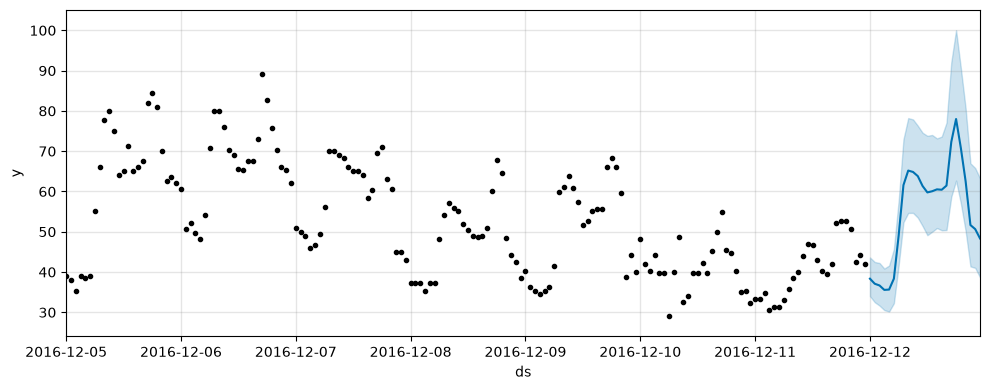

In [12]:
fig = m.plot(fcst_x, figsize=(10, 4))
ax = fig.gca()
# zoom on the last week and the forecast
last_week = epf.tail(24 * 7)
ax.set_xlim(last_week["ds"].iloc[0], fcst_x["ds"].iloc[-1])
ax.set_ylim(last_week["y"].min() - 5, fcst_x["yhat_upper"].max() + 5)
plt.show()

## Compare models with Prophet's diagnostics

`prophet.diagnostics.cross_validation` and `performance_metrics` work with `FoundationProphet`: every clone
the diagnostics make reuses the model you passed. Swapping the model is a one-line change.

In [13]:
cv_args = dict(horizon="365 days", period="365 days", initial="1825 days", disable_tqdm=True)

candidates = {
    "Prophet": Prophet(),
    "Chronos-Bolt": FoundationProphet(model=model, insample="none"),
    "Chronos-2": FoundationProphet(
        model=Chronos(repo_id="amazon/chronos-2", alias="Chronos-2"),
        insample="none",
    ),
}

rows = {}
for name, candidate in candidates.items():
    candidate.fit(df)
    df_cv = cross_validation(candidate, **cv_args)
    rows[name] = performance_metrics(df_cv, rolling_window=1)[["mae", "mape"]].iloc[0]

pd.DataFrame(rows).T

INFO:prophet:Disabling weekly seasonality. Run prophet with weekly_seasonality=True to override this.


INFO:prophet:Disabling daily seasonality. Run prophet with daily_seasonality=True to override this.


INFO:cmdstanpy:Chain [1] start processing


INFO:cmdstanpy:Chain [1] done processing


INFO:prophet:Making 6 forecasts with cutoffs between 1954-12-03 00:00:00 and 1959-12-02 00:00:00


INFO:cmdstanpy:Chain [1] start processing


... (39 outputs left out)

100%|██████████| 1/1 [00:00<00:00, 20.85it/s]

  0%|          | 0/1 [00:00<?, ?it/s]

100%|██████████| 1/1 [00:00<00:00, 20.90it/s]

,mae,mape
Prophet,27.727863,0.071233
Chronos-Bolt,25.217020,0.064103
Chronos-2,18.572602,0.048825


## What is different from Prophet

- `growth`, `holidays`, seasonalities, changepoints and the other Prophet arguments are accepted so existing
  code keeps running, but they do not affect a foundation model.
- `plot_components` and the posterior sampling methods raise `NotImplementedError`: there are no trend or
  seasonality components.
- The history must be on a regular grid with no gaps (rows with a null `y` are dropped, so an interior one
  counts as a gap). Its frequency is inferred from `ds`, and dates after the history must continue it, as
  `make_future_dataframe` does.